# Hypotheses

Dans ce modèle, tout agent de la population suit le processus suivant :

1. Un push tag permet à l’étudiant de placer son code dans une file d’attente FIFO infinie pour l’exécution de la test-suite associée : un nombre K de serveurs est disponible pour cette tâche.

### File 1 : M/M/K
On utilise une file (infinie) markovienne en entrée et en sortie pour simuler les push des etudiants. On dispose également de K serveur pour cette première file. 


| Notation | Propriété du système réel qu'il représente 
|---|---|
| M (arrivées) | Un grand nombre d'étudiants envoient leurs pushs de façon indépendante, ce qui se modélise par un processus de Poisson de taux λ|
| M (service) | La durée d'une test-suite est aléatoire, supposée exponentielle de moyenne 1/μ |
| K | K serveurs identiques traitent des tests en parallèle, soit une capacité de traitement de K·μ |


2. Une fois la test-suite exécutée, le résultat est placé dans une file d’attente FIFO infinie gérée par un serveur unique pour l’envoi vers le front.
   
### File 2 : M/M/1
On utilise également une file (infine) markovienne en entrée et en sortie mais cette fois ci elle ne contient qu'un seul serveur.

| Notation | Propriété du système réel qu'il représente 
|---|---|
| M (arrivées) | Un grand nombre d'étudiants envoient leurs pushs de façon indépendante, ce qui se modélise par un processus de Poisson de taux λ|
| M (service) | La durée d'une test-suite est aléatoire, supposée exponentielle de moyenne 1/μ |
| 1 | 1 serveur récupère les résultats des tests pour l'envoyer au front, soit une capacité de traitement de μ |


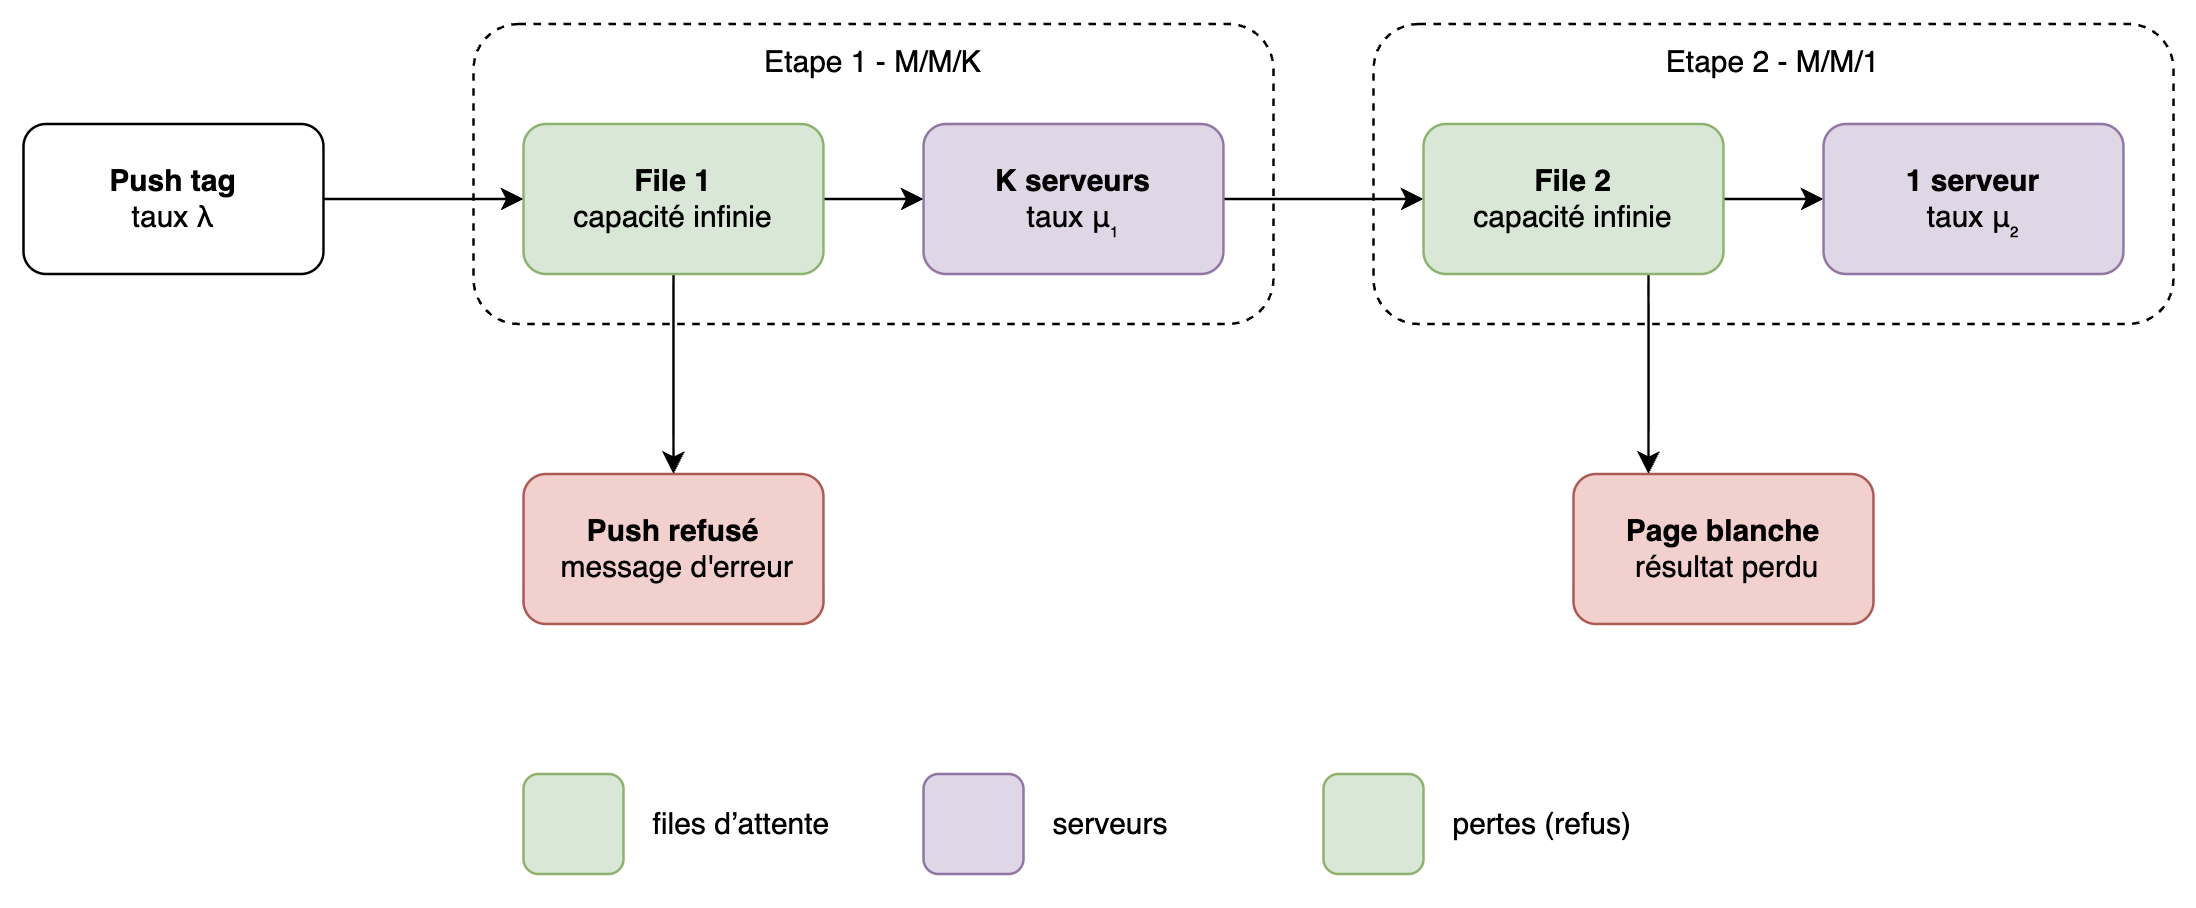

In [8]:
from IPython.display import Image
Image("images/1.png")

# Simulation 1

Consigne : Proposez un système d’attente modélisant le contexte décrit ci-dessus. Effectuez quelques simulations pour analyser son comportement selon les paramètres en jeu. 

In [7]:
class mm1():
    """
    A class representing an mm1 queue.

    Attributes :

        lamda (float)   : parameter of exponential law corresponding to interarrival times.
        mu (float)      : parameter of exponential law corresponding to service times.
        gen (np.random) : a random generator
        test_z (int)    : test size
        tops            : dataframe containing queue and service arrival times, and departure times for each agent.
    """


    def __init__(self, lamda, mu, gen, test_z=100) :
        """
        Initializes a news instance of the class mm1.

        Args :
            lamda  : parameter of exponential law corresponding to interarrival times.
            mu     : parameter of exponential law corresponding to service times.
            gen    : a random generator
            test_z : test size.
        """

        #Initializing metadata
        self.lamda = lamda
        self.mu = mu
        self.gen = gen
        self.t_size = test_z

        #Initializin tops dataframe
        column_names = ['t_arval_queue', 't_arval_srv', 't_depart_sys']
        self.tops = pd.DataFrame(np.empty((self.t_size, 3),dtype=object), columns=column_names)

    def run(self):
        """
        Simulates the mm1 queuing system

        Modifies the attribute tops following a simulation of mm1 queue respecting interarrival and
        outgoing intensities given by corresponding attributes. Besides filling in queue arrival times,
        service arrival times and departure times for each agent, it adds columns to tops corresponding
        to sojourn time (t_sojourn), waiting time (t_waiting) and service time (t_service) of each agent.
        """
        # Generate interarrival times and service times
        interarrivals = self.gen.exponential(1.0 / self.lamda, self.t_size)
        services = self.gen.exponential(1.0 / self.mu, self.t_size)

        # Absolute arrival times
        t_arval_queue = np.cumsum(interarrivals)
        
        t_arval_srv = np.zeros(self.t_size)
        t_depart_sys = np.zeros(self.t_size)

        # First agent
        t_arval_srv[0] = t_arval_queue[0]
        t_depart_sys[0] = t_arval_srv[0] + services[0]

        # Sequential computation for M/M/1
        for i in range(1, self.t_size):
            t_arval_srv[i] = max(t_arval_queue[i], t_depart_sys[i-1])
            t_depart_sys[i] = t_arval_srv[i] + services[i]

        # Store inside the dataframe
        self.tops['t_arval_queue'] = t_arval_queue
        self.tops['t_arval_srv'] = t_arval_srv
        self.tops['t_depart_sys'] = t_depart_sys

        # Durations
        self.tops['t_sojourn'] = self.tops['t_depart_sys'] - self.tops['t_arval_queue']
        self.tops['t_waiting'] = self.tops['t_arval_srv'] - self.tops['t_arval_queue']
        self.tops['t_service'] = self.tops['t_depart_sys'] - self.tops['t_arval_srv']


    def counts(self, t_intervals):
        """
        Computes number of agents in system at all given times.

        Args :
            t_intervals : size of time laps between two successive tops.

        Returns :
            A dataframe indexed by time laps of size t_intervals all along total queue simulation time,
            its three columns contain number of agents in system (ag_in_sys), in arrival queue (ag_in_queue) and
            in service (ag_in_service).
        """
        max_time = self.tops['t_depart_sys'].max()
        time_steps = np.arange(0, max_time + t_intervals, t_intervals)
        
        ag_in_sys = []
        ag_in_queue = []
        ag_in_service = []

        for t in time_steps:
            # Agent is in system if arrived in queue but not yet departed
            in_sys = ((self.tops['t_arval_queue'] <= t) & (t < self.tops['t_depart_sys'])).sum()
            # Agent is in queue if arrived but not yet at service
            in_queue = ((self.tops['t_arval_queue'] <= t) & (t < self.tops['t_arval_srv'])).sum()
            # Agent is in service if service started but not yet departed
            in_service = ((self.tops['t_arval_srv'] <= t) & (t < self.tops['t_depart_sys'])).sum()

            ag_in_sys.append(in_sys)
            ag_in_queue.append(in_queue)
            ag_in_service.append(in_service)

        counts_df = pd.DataFrame({
            'ag_in_sys': ag_in_sys,
            'ag_in_queue': ag_in_queue,
            'ag_in_service': ag_in_service
        }, index=time_steps)
        counts_df.index.name = 'time'
        return counts_df

    def stats(self):
        """
        Computes statistics of a current simulation of queue.

        Returns:
            A dataframe indexed by standard statistics of interest mean sojourn time (mean_sojourn_time),
            mean waiting time (mean_waiting_time) and mean service time (mean_service_time).
        """
        stat_values = [
            self.tops['t_sojourn'].mean(),
            self.tops['t_waiting'].mean(),
            self.tops['t_service'].mean()
        ]
        stat_names = ['mean_sojourn_time', 'mean_waiting_time', 'mean_service_time']
        return pd.DataFrame(stat_values, index=stat_names, columns=['value'])